# Введение

Teachable Machine – это веб-версия инструмента, которая позволяет всем желающим легко создать модель машинного обучения.

Чтобы научить компьютер распознавать изображения, звуки и позы с помощью Teachable Machine не нужно писать код. Вы можете использовать модель в своих проектах, на сайтах, в приложениях и не только.

Сервис Teachable Machine доступен по ссылке [teachablemachine.withgoogle.com](teachablemachine.withgoogle.com).  Язык пользовательского интерфейса - русский.

Перед обучением модели рекомендуем внимательно изучить дополнительную информацию, расположенную на главной странице сервиса:

* Что такое Teachable Machine?

* Как пользоваться инструментом?

* С помощью чего можно обучить модель?

* Руководства

# Проекты с изображениями.

## Задание 1. 

1. Перейдите по ссылке [teachablemachine.withgoogle.com](teachablemachine.withgoogle.com) и нажмите "Начать".

2. Выберите "Проект с изображениями", далее "Стандартная модель изображения".

Необходимо обучить модель различать две группы изображений: хот-доги и не хот-доги с помощью готового (размеченного) набора изображений.

3. Переименуйте "Class 1" в "хот-доги", а "Class 2" в "не хот-доги".

4. В классе "хот-доги" нажмите на кнопку "Загрузить", затем выберите пункт "Выберите изображения из файлов".

5. Выберите папку "hot_dog_train". Необходимо выбрать все изображения в папке с помощью клавиш Ctrl+A и нажать "Открыть".

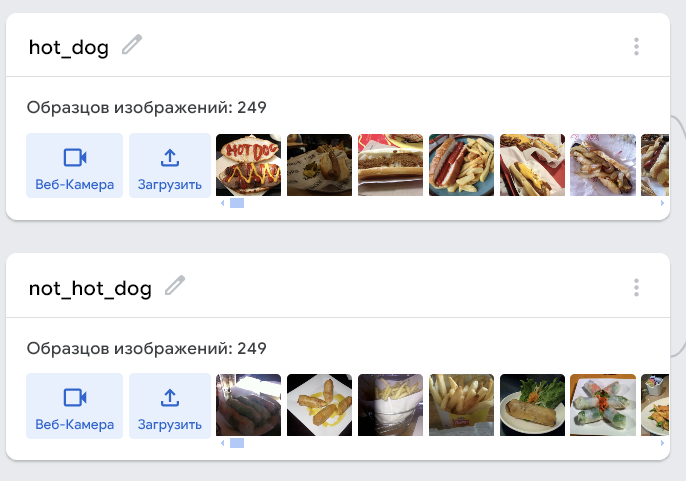

6. Аналогично нужно добавить изображения из папки "not_hot_dog_train" в класс "не хот-доги".
7. Запустите обучение модели, нажав на кнопку "Обучить модель". Обучение происходит на текущей вкладке браузера некоторое время, поэтому не следует переключаться между вкладками во время процесса обучения.
8. В разделе "Обучение" раскройте список "Дополнительно" и выберите "Дополнительные сведения". Они откроются справа. Изучите данный раздел. Обратите внимание на раздел "Точность на каждый класс".

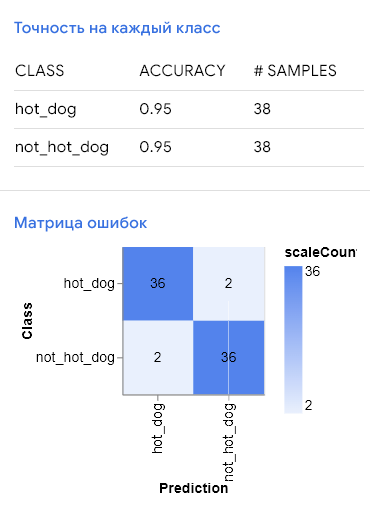

9. Справа от раздела "Обучение" находится раздел "Посмотреть", в котором можно проверить, как работает обученная модель. Для этого вместо "webcam" нужно выбрать "файл" и выбрать один файл из папки "hot_dog_validation".

10. Посмотрите результат (прогноз) в разделе "Выходные данные" и сделайте вывод, насколько правильно модель определила наличие хот-дога на изображении. Загрузите поочередно еще 10 изображений и проверьте правильность определения "хот-догов". __Напишите вывод в отчете__.

11. Аналогичным образом загрузите поочередно 10 изображений из папки "not_hot_dog_validation". Сделайте вывод о правильности определения "не хот-догов". __Напишите вывод в отчете__.

12. Сохраните модель. 
13. Изучите и скопируйте фрагмент кода, который можно использовать в вашей модели. Используя фрагмент кода, загрузите модель в jupyter notebook и проверьте ее работу на всех изображениях (папки hot_dog_validation и not_hot_dog_validation).

### Отчет по заданию 1 (шаги 8–11)

Я открыл сайт Teachable Machine, создал проект для изображений (стандартная модель) и сделал два класса: **хот-доги** (249 фото из папки `hot_dog_train`) и **не хот-доги** (249 фото из папки `not_hot_dog_train`). Обучил модель со стандартными настройками (50 эпох, размер батча 16, скорость обучения 0.001).

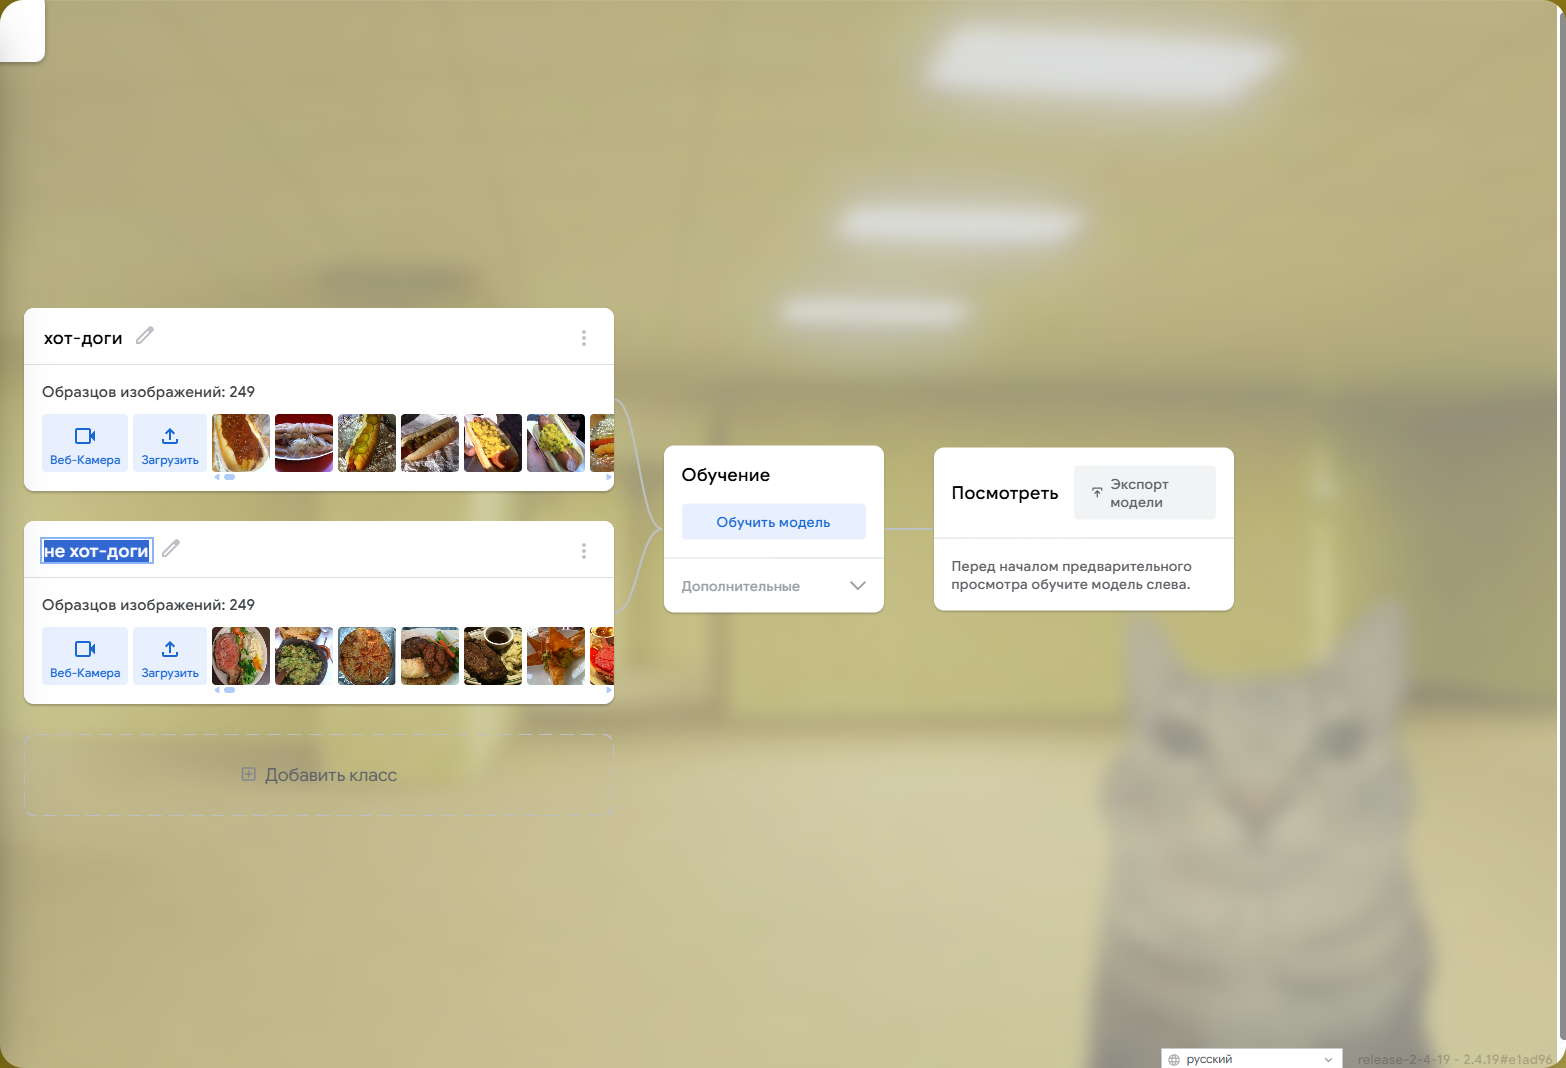

Потом я открыл раздел **Дополнительно -> Дополнительные сведения** и посмотрел таблицу точности и матрицу ошибок (внутренняя тестовая выборка сайта по 38 картинок на класс):
- **хот-доги**: точность **0.84** (32 правильных ответа и 6 ошибок);
- **не хот-доги**: точность **0.92** (35 правильных ответов и 3 ошибки).

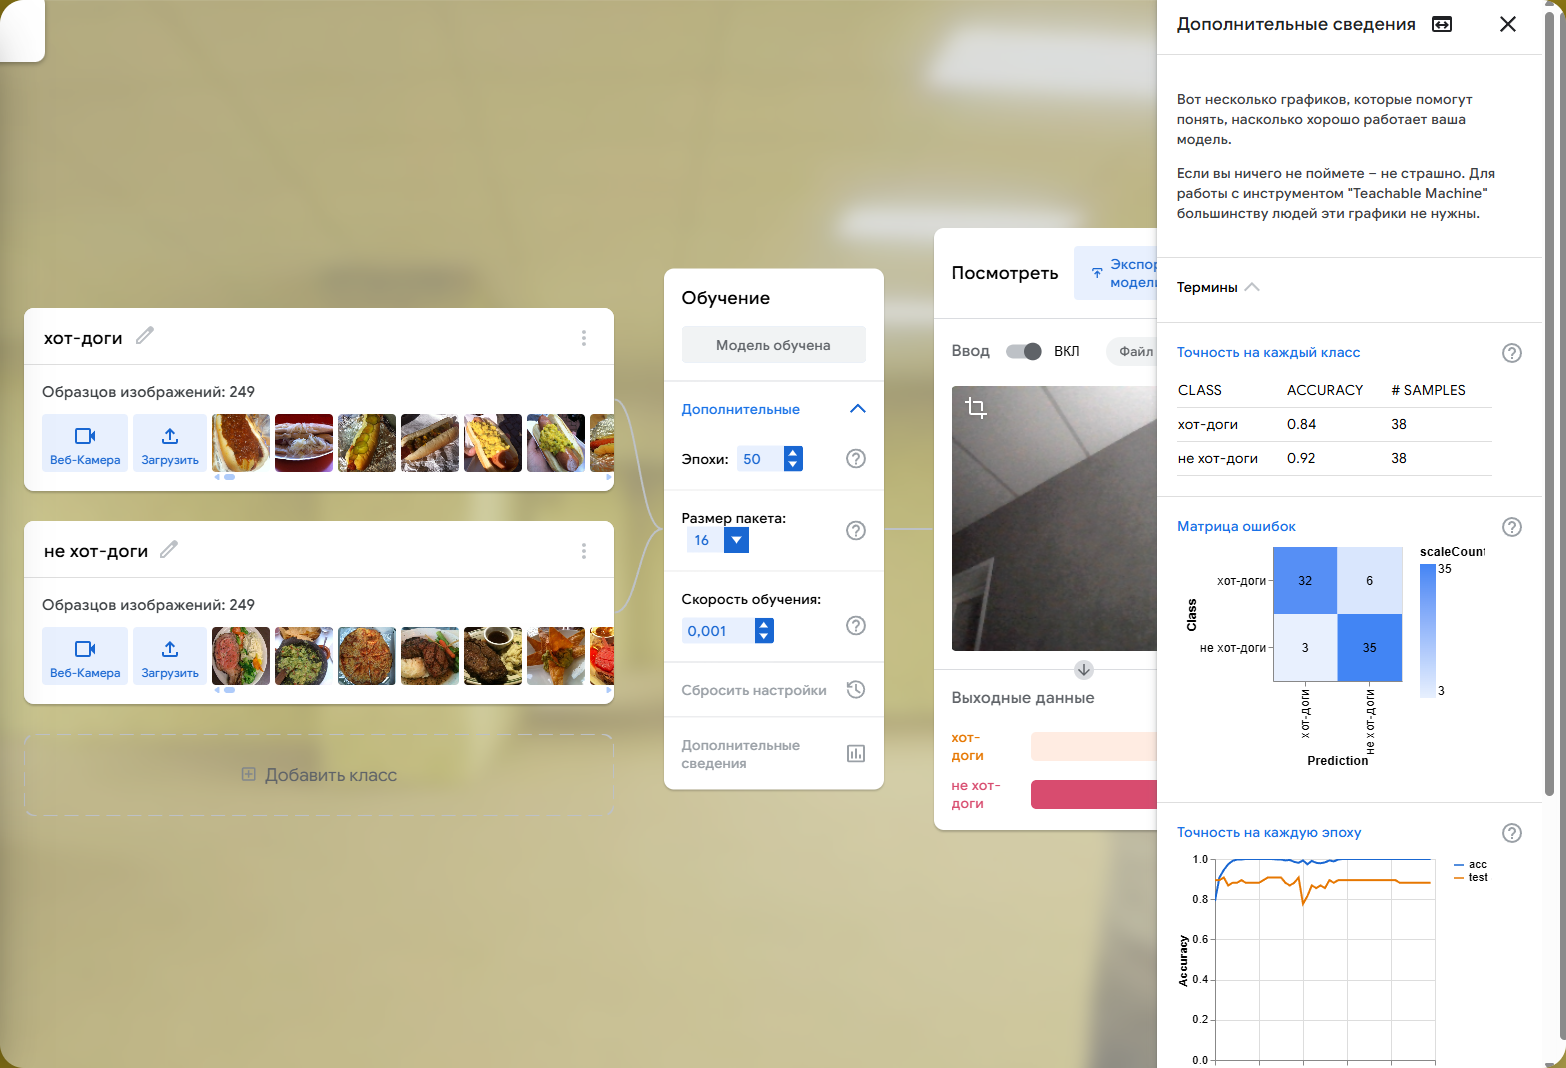

После обучения я проверил модель в разделе **Посмотреть** (выбрал загрузку из файла):
- **Проверка 1 + 10 картинок из `hot_dog_validation`**: первой картинкой была `133012.jpg` — модель уверенно выбрала **хот-доги** (100%). Из следующих 10 картинок на 9 уверенность тоже была высокой (от 91% до 100%, например на `143012.jpg` получилось 91%), а на одной картинке (`133015.jpg`) модель почти засомневалась: **хот-доги** 50% (50.23%) и **не хот-доги** 50% (49.77%), но всё же отнесла её к хот-догам.
- **Проверка 10 картинок из `not_hot_dog_validation`**: все 10 картинок модель определила правильно как **не хот-доги** с уверенностью от 96% (`14484.jpg` — 96%) до 100% (остальные 9 картинок).

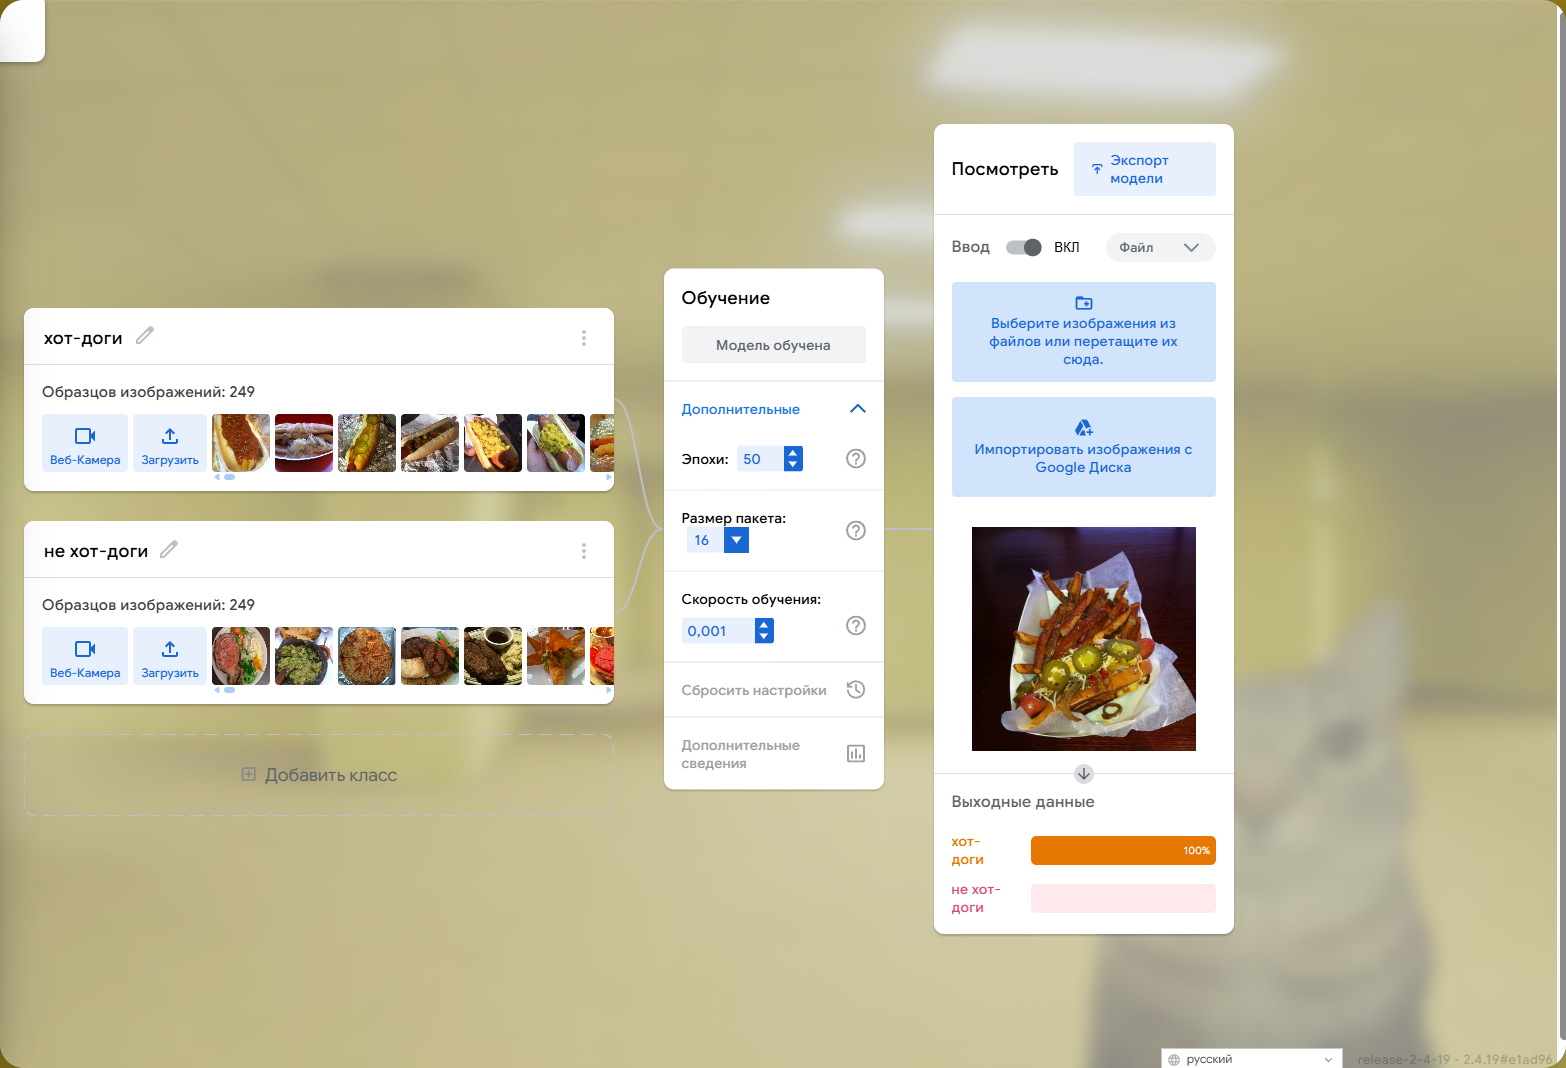

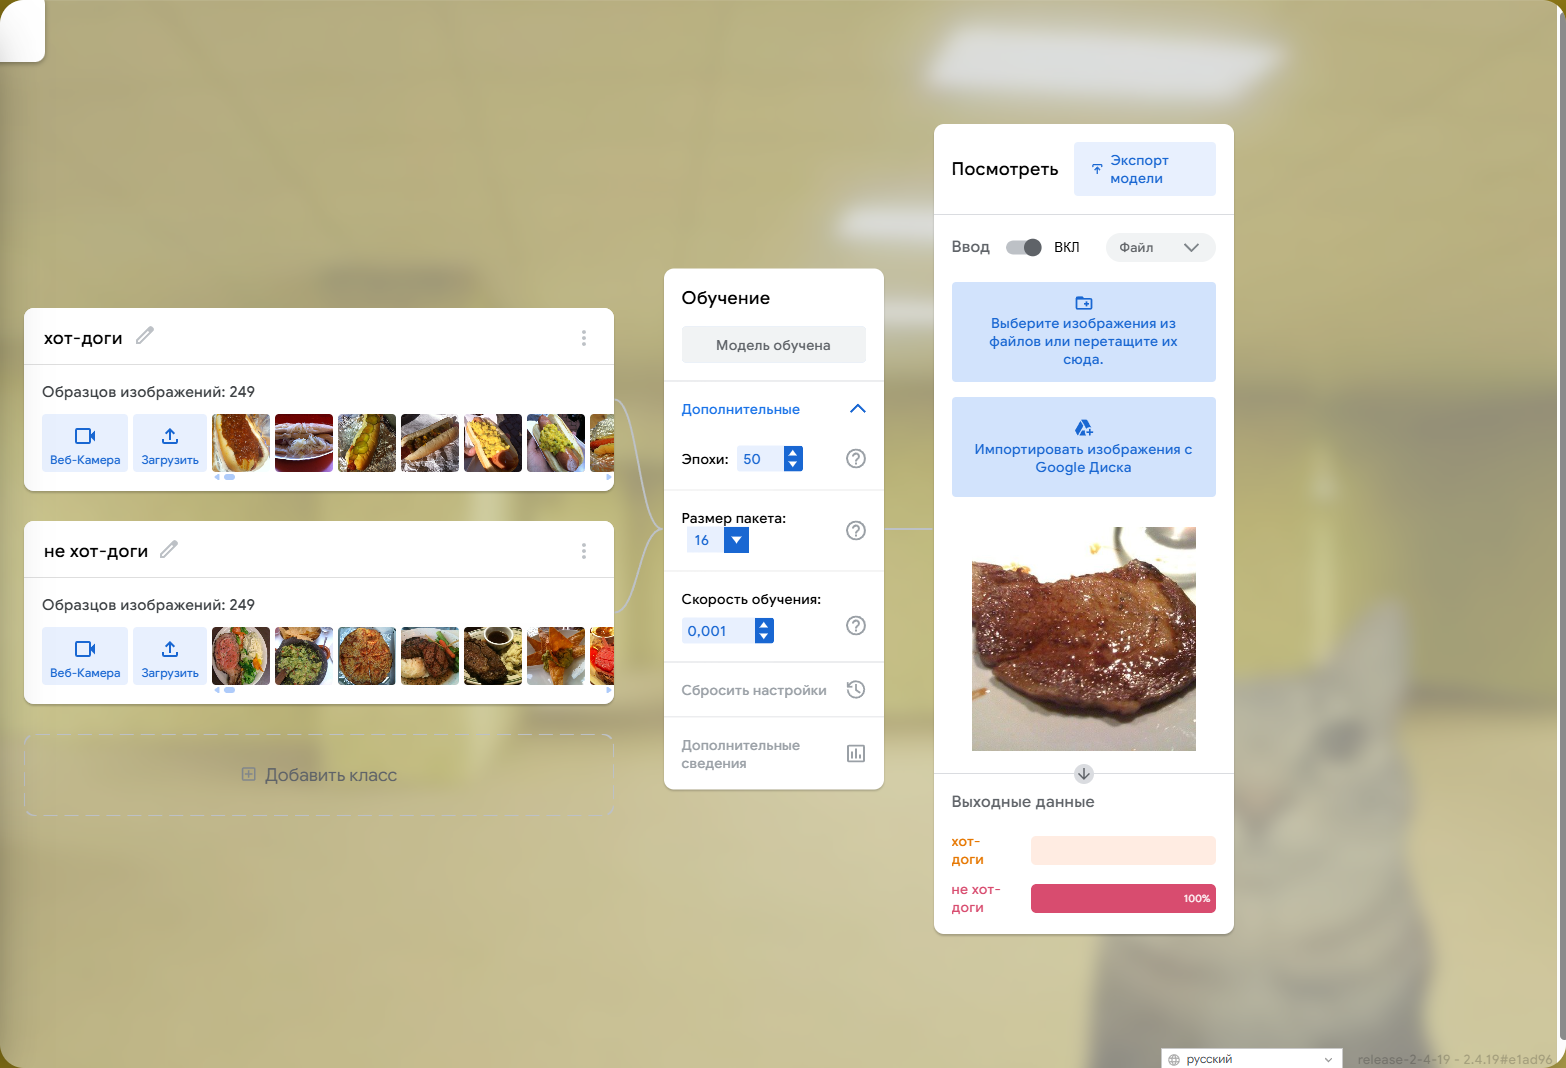

**Вывод по шагам 10–11:** модель хорошо отличает хот-доги от обычной еды, потому что на 20 проверенных примерах (кроме одной пограничной картинки 50% на 50%) она давала правильный и уверенный ответ. Но на таблице точности видно, что класс хот-догов модель иногда путает (точность 0.84), если хот-дог сфотографирован с необычного ракурса или рядом много другой еды.

In [1]:
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np
import os

model = load_model("models/hotdog/keras_model.h5", compile=False)
class_names = open("models/hotdog/labels.txt", "r", encoding="utf-8").readlines()

data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

hotdog_ok = 0
hotdog_all = 0

for filename in os.listdir("hot_dog_validation"):
    path = "hot_dog_validation/" + filename
    image = Image.open(path).convert("RGB")
    image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
    image_array = np.asarray(image)
    normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
    data[0] = normalized_image_array

    prediction = model.predict(data, verbose=0)
    index = np.argmax(prediction)
    hotdog_all = hotdog_all + 1
    if index == 0:
        hotdog_ok = hotdog_ok + 1

not_hotdog_ok = 0
not_hotdog_all = 0

for filename in os.listdir("not_hot_dog_validation"):
    path = "not_hot_dog_validation/" + filename
    image = Image.open(path).convert("RGB")
    image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
    image_array = np.asarray(image)
    normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
    data[0] = normalized_image_array

    prediction = model.predict(data, verbose=0)
    index = np.argmax(prediction)
    not_hotdog_all = not_hotdog_all + 1
    if index == 1:
        not_hotdog_ok = not_hotdog_ok + 1

total_ok = hotdog_ok + not_hotdog_ok
total_all = hotdog_all + not_hotdog_all

print("Хот-доги правильно:", hotdog_ok, "из", hotdog_all, "(", round(hotdog_ok / hotdog_all * 100, 1), "% )")
print("Не хот-доги правильно:", not_hotdog_ok, "из", not_hotdog_all, "(", round(not_hotdog_ok / not_hotdog_all * 100, 1), "% )")
print("Всего правильно:", total_ok, "из", total_all, "(", round(total_ok / total_all * 100, 1), "% )")

Хот-доги правильно: 218 из 250 ( 87.2 % )
Не хот-доги правильно: 218 из 250 ( 87.2 % )
Всего правильно: 436 из 500 ( 87.2 % )


### Итоги проверки модели на всех 500 изображениях

На полной проверке через Python модель показала такой результат:
- из папки `hot_dog_validation`: правильно определено **218 из 250** (**87.2%**);
- из папки `not_hot_dog_validation`: правильно определено **218 из 250** (**87.2%**);
- всего по двум папкам: **436 из 500** (**87.2%**), ошибок — **64**.

**Общий вывод по заданию 1:** модель стабильно работает почти на 9 из 10 новых картинок. Ошибки (32 в одной папке и 32 в другой) появляются там, где хот-дог снят слишком издалека, закрыт соусами и начинкой, или когда на фото другой еды есть вытянутые булочки и сосиски, похожие на хот-дог.

## Задание 2. 

1. Соберите коллекцию изображений как минимум трех классов (можно сделать больше классов). В каждом классе должно быть минимум 20 изображений. Можно использовать изображения из интернета или создать собственные изображения с помощью камеры.

2. Обучите модель в сервисе Teachable Machine.

3. В отчете укажите названия классов и точность на каждый класс. Добавьте скриншоты.

4. Сделайте вывод, как точно модель определяет неизвестные ей изображения.

5. Сохраните модель.
6. Используя фрагмент кода, загрузите модель в jupyter notebook и проверьте ее работу на нескольких изображениях.

### Отчет по заданию 2

Я собрал свой набор картинок из трёх классов (`my_dataset`):
1. **кошки** — 20 картинок для обучения (и 5 отдельных для проверки);
2. **собаки** — 20 картинок для обучения (и 5 отдельных для проверки);
3. **машины** — 20 картинок для обучения (и 5 отдельных для проверки).

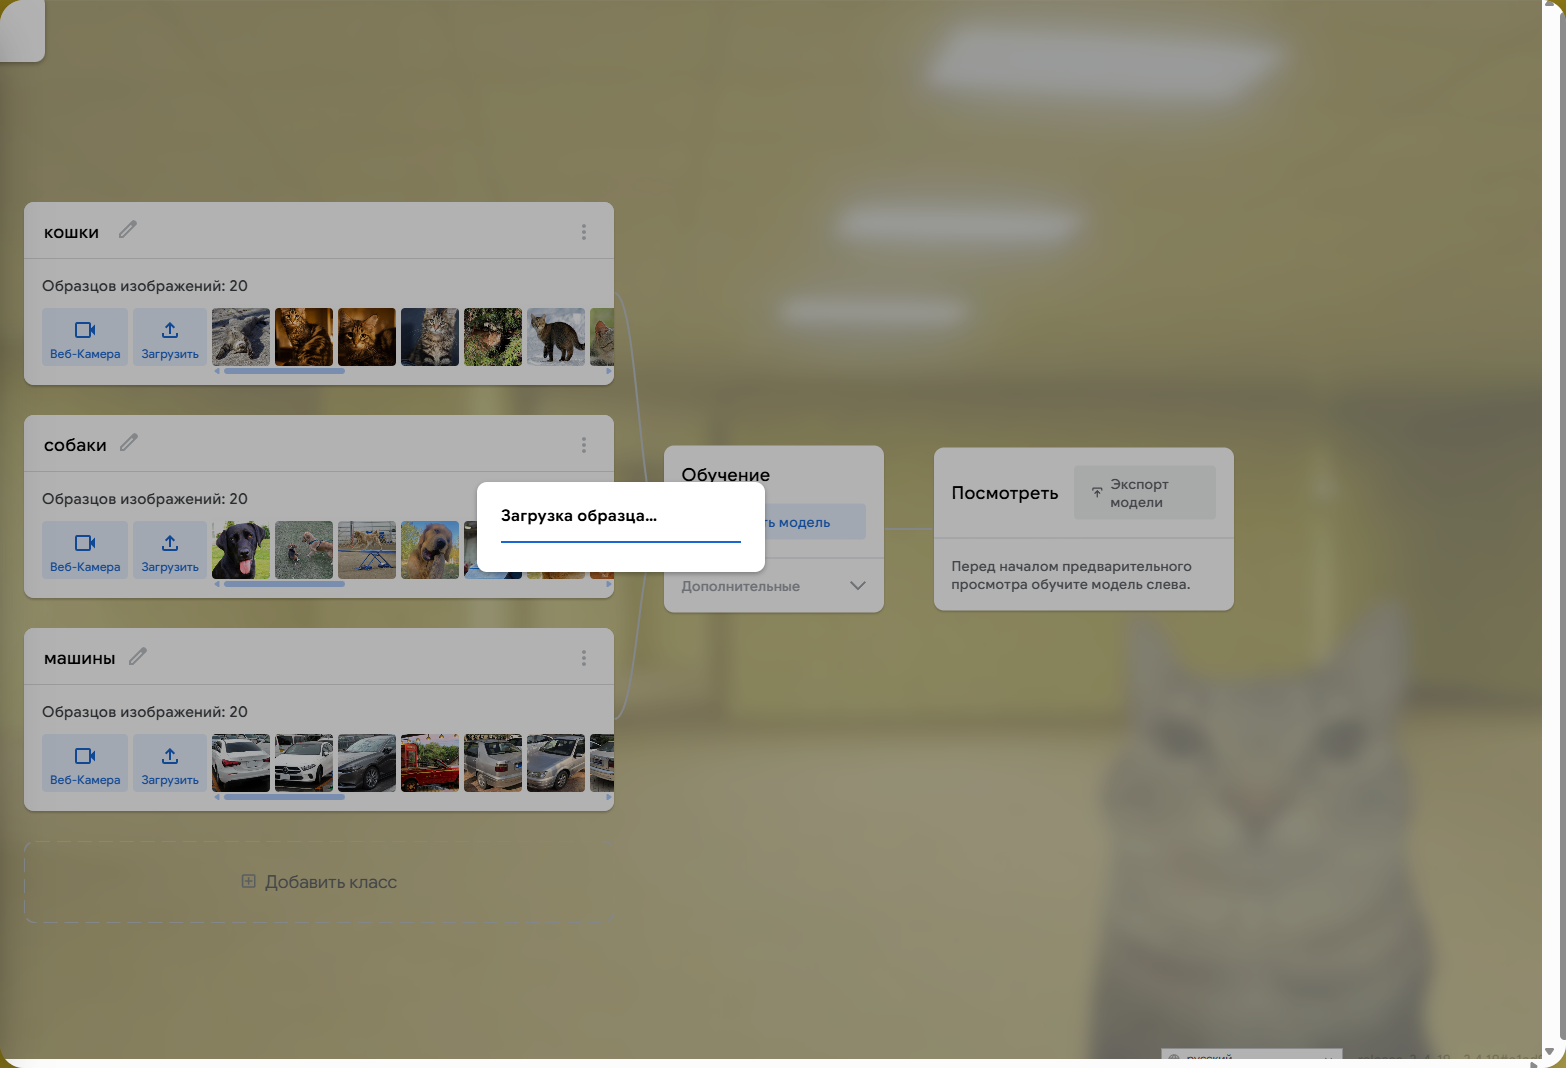

После обучения в Teachable Machine (50 эпох) я открыл вкладку с точностью модели. Для всех трёх классов точность на тестовой части самого сервиса получилась **1.00** (по 3 проверочных примера на каждый класс, ошибок в таблице не было):
- **кошки**: `1.00` (3 примера);
- **собаки**: `1.00` (3 примера);
- **машины**: `1.00` (3 примера).

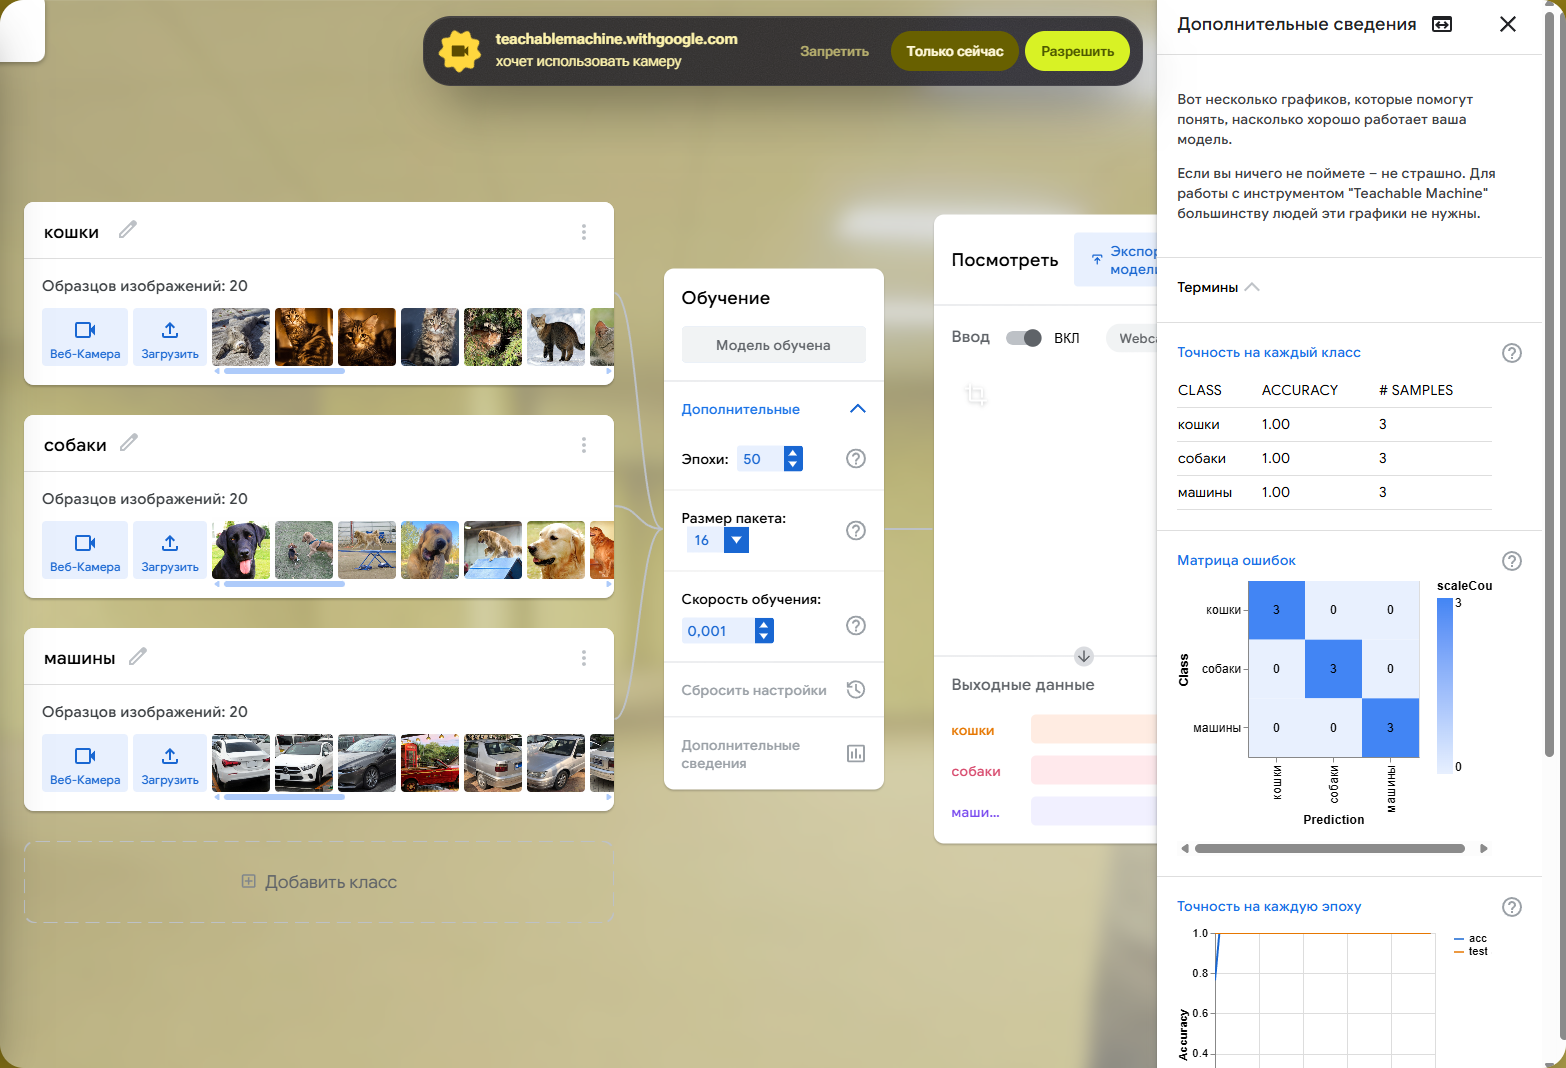

Дальше в окне **Посмотреть** я по очереди проверил все 15 новых картинок из папки `my_dataset/test` (по 5 для каждого класса). Модель правильно определила все 15 картинок с уверенностью от 99.6% до 100%.

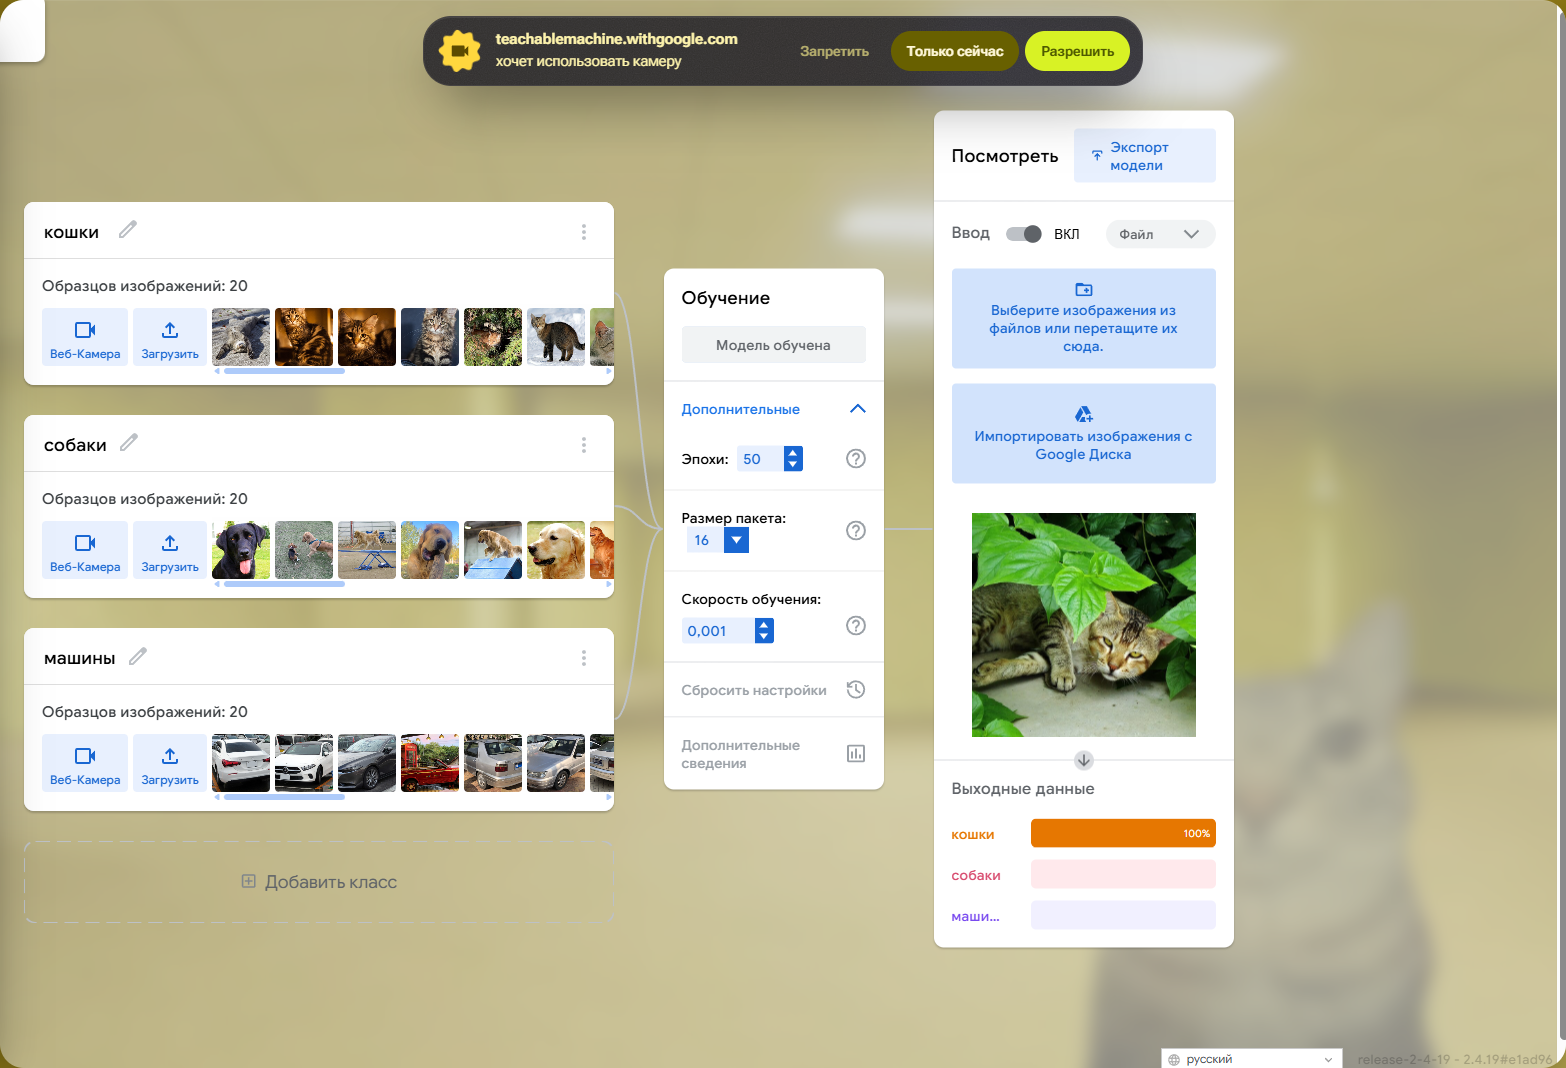

**Вывод:** на новых фотографиях модель сработала очень точно, потому что классы сильно отличаются друг от друга по форме и деталям (машина совсем не похожа на животное, а у кошек и собак разные мордочки). Но так как для обучения было всего по 20 картинок на класс, на очень сложных фото (например, где животное далеко или плохо видно) модель всё равно может ошибиться.

In [2]:
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np
import os

model2 = load_model("models/my_model/keras_model.h5", compile=False)
class_names2 = open("models/my_model/labels.txt", "r", encoding="utf-8").readlines()

data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

folders = ["кошки", "собаки", "машины"]
right = 0
total = 0

for folder in folders:
    folder_path = "my_dataset/test/" + folder
    for filename in os.listdir(folder_path):
        image = Image.open(folder_path + "/" + filename).convert("RGB")
        image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
        image_array = np.asarray(image)
        normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
        data[0] = normalized_image_array

        prediction = model2.predict(data, verbose=0)
        index = np.argmax(prediction)
        class_name = class_names2[index][2:].strip()
        confidence = prediction[0][index] * 100

        print(folder + "/" + filename, "->", class_name, round(confidence, 1), "%")

        total = total + 1
        if class_name == folder:
            right = right + 1

print("Итого правильно:", right, "из", total)

кошки/01.jpg -> кошки 100.0 %
кошки/02.jpg -> кошки 100.0 %
кошки/03.jpg -> кошки 99.9 %


кошки/04.jpg -> кошки 100.0 %
кошки/05.jpg -> кошки 100.0 %
собаки/01.jpg -> собаки 99.8 %


собаки/02.jpg -> собаки 99.8 %
собаки/03.jpg -> собаки 99.7 %
собаки/04.jpg -> собаки 99.6 %


собаки/05.jpg -> собаки 99.4 %
машины/01.jpg -> машины 99.9 %
машины/02.jpg -> машины 99.7 %


машины/03.jpg -> машины 100.0 %
машины/04.jpg -> машины 100.0 %
машины/05.jpg -> машины 100.0 %
Итого правильно: 15 из 15


## Задание 3.

Pocket AutoML — это Android-приложение, которое позволяет тренировать модели глубокого обучения (deep learning) для классификации изображений без написания кода. Есть возможность экспортировать модель в формате TensorFlow Lite и создать на основе этой модели собственное Android-приложение, для чего прилагается пошаговое руководство.

Тренировка работает прямо на устройстве, за счёт этого для неё не требуется подключение к интернету, нет проблем с конфиденциальностью, т.к. изображения не покидают устройства пользователя. Теми же преимуществами будут обладать и приложения, созданные на основе экспортированных из Pocket AutoML моделей. Единственная функция, требующая подключения к интернету, это экспорт в TensorFlow Lite.

1. Установите приложение Pocket AutoML на свой смартфон.
2. Создайте новую задачу.
3. Создайте минимум 3 класса объектов, которые будут использоваться в модели распознавания образов.
4. На вкладке "Данные" в каждый класс добавьте минимум по 10 изображений (можно использовать камеру или загрузить готовые изображения).
5. На вкладке "Модель" выполните тренировку модели.
6. На вкладке "Распознать" проверьте качество распознавания изображений, показывая модели поочередно несколько объектов (можно использовать камеру или загрузить готовые изображения). При распознавании помогите модели работать лучше, подтвердив или исправив результат распознавания. После каждого нового распознавания и подтверждения изображение добавляется в соответствующий класс. Распознайте как минимум 10 изображений.
7. Снова выполните тренировку модели. После этого снова проверьте качество распознавания, предлагая модели новые изображения.
8. Сделайте скриншоты вкладок "Данные" и "Модель". Разместите эти скриншоты в отчет.
9. В отчете напишите вывод о качестве распознавания изображений вашей модели. Попытайтесь объяснить причины, почему модель в некоторых случаях ошибается.

### Отчет по заданию 3 (Pocket AutoML)

Я установил приложение **Pocket AutoML** на смартфон Android и создал новую задачу `Task 1` с тремя классами:
- `Cars` (машины) — 10 фотографий;
- `Cats` (кошки) — 10 фотографий;
- `Dogs` (собаки) — 10 фотографий.

Сначала я обучил модель на вкладке **Model** на этих **30 изображениях**. Затем перешёл на вкладку **Prediction** и по очереди проверил **12 новых картинок** (по 4 машины, 4 собаки и 4 кошки). Все 12 картинок определились верно, и после каждой проверки я нажимал кнопку **Confirm** (подтвердить), чтобы они добавлялись в классы для дообучения.

Перед вторым обучением статистика на вкладке **Model** показывала:
- `Training images: 30`
- `Total predictions: 12`
- `Feedback (confirmed/total): 11/11`
- `Accuracy: 73.54% to 99.79% (95% credibility)`

После этого я снова нажал **Train**. Модель дообучилась уже на **41 изображении**, а потом я проверил ещё **3 новых фотографии** (зелёную ретро-машину, белую собаку и кота с голубыми глазами) — модель тоже угадала все 3 класса.

На итоговой вкладке **Model** получилось:
- `Training images: 41`
- `Total predictions: 15`
- `Feedback (confirmed/total): 14/14`
- `Accuracy: 78.20% to 99.84% (95% credibility)`

Видно, что после добавления новых примеров и повторного обучения оценка точности выросла с `73.54%–99.79%` до `78.20%–99.84%`.

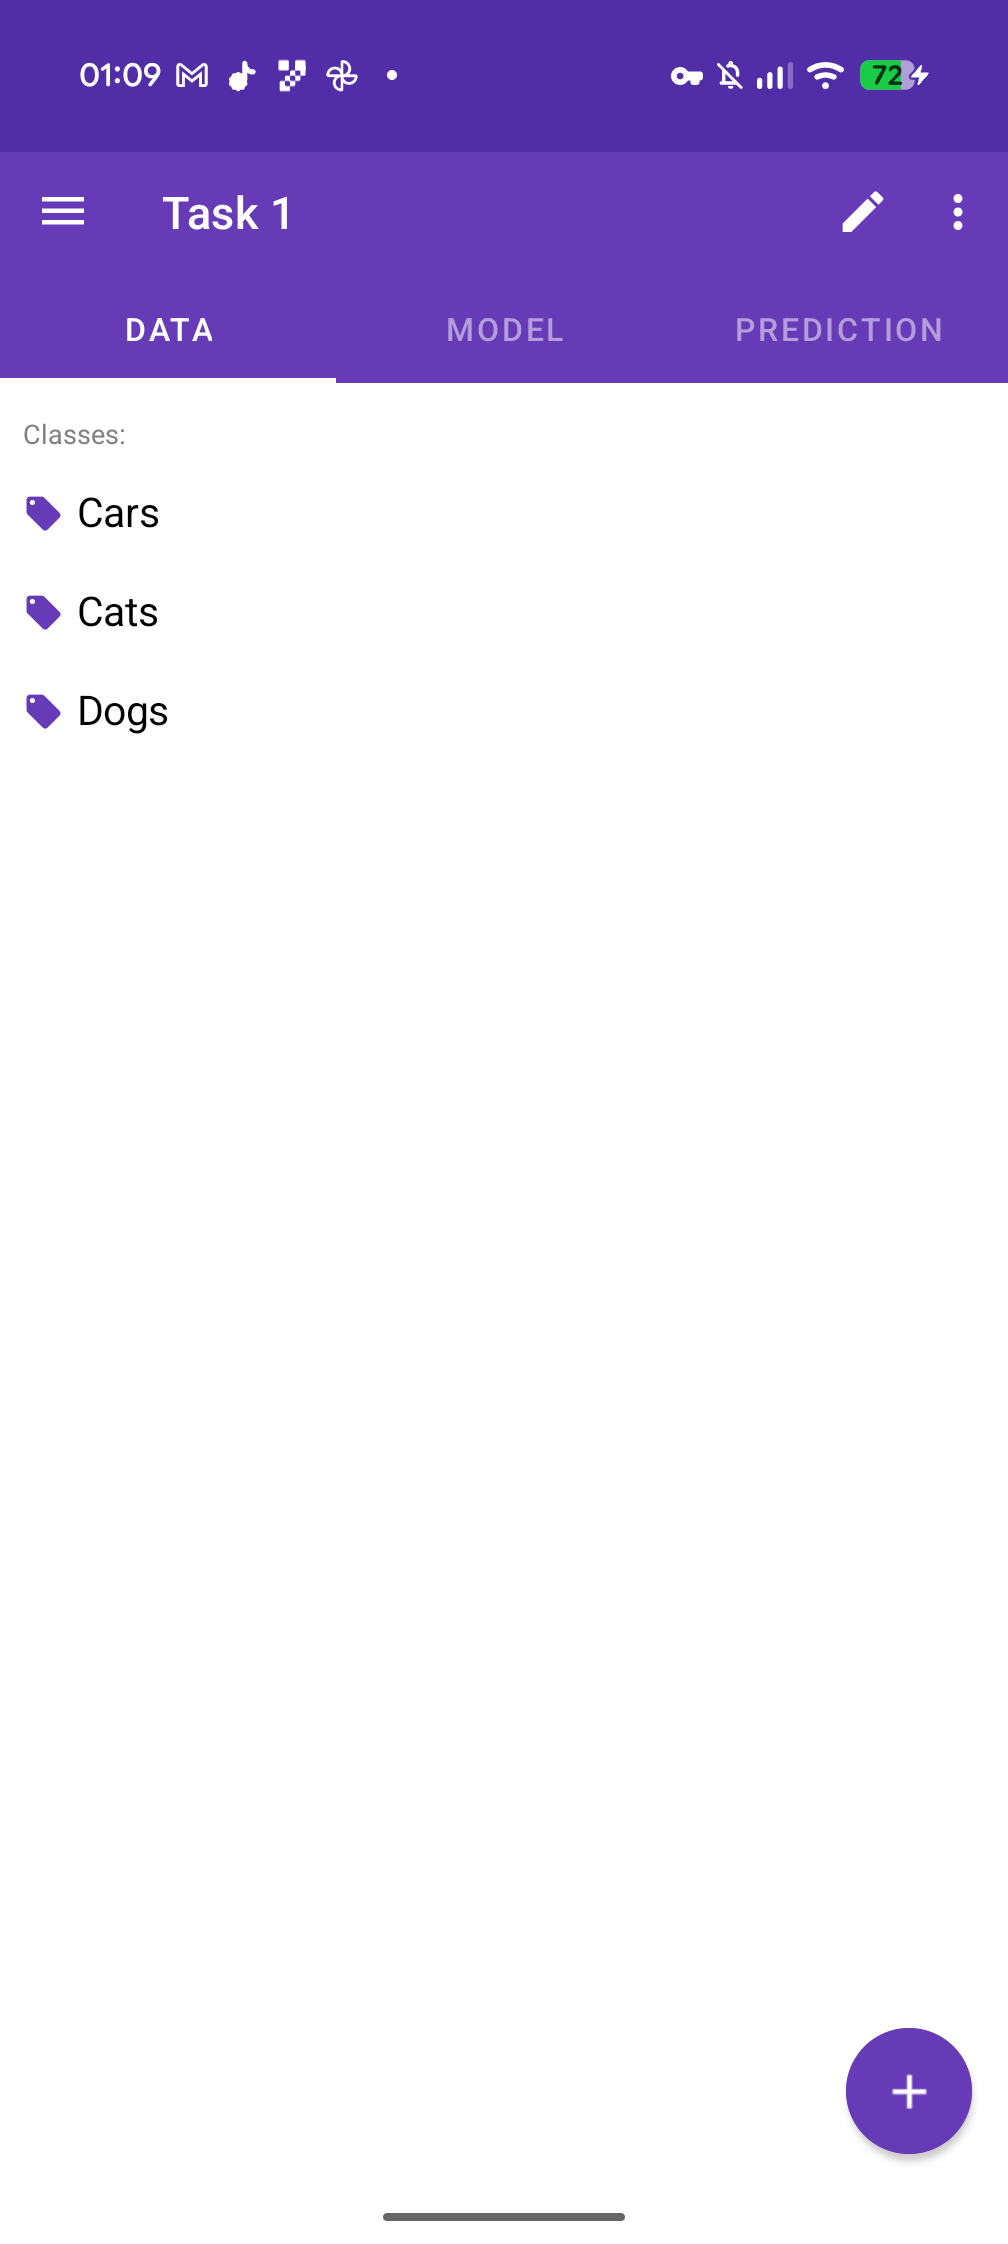

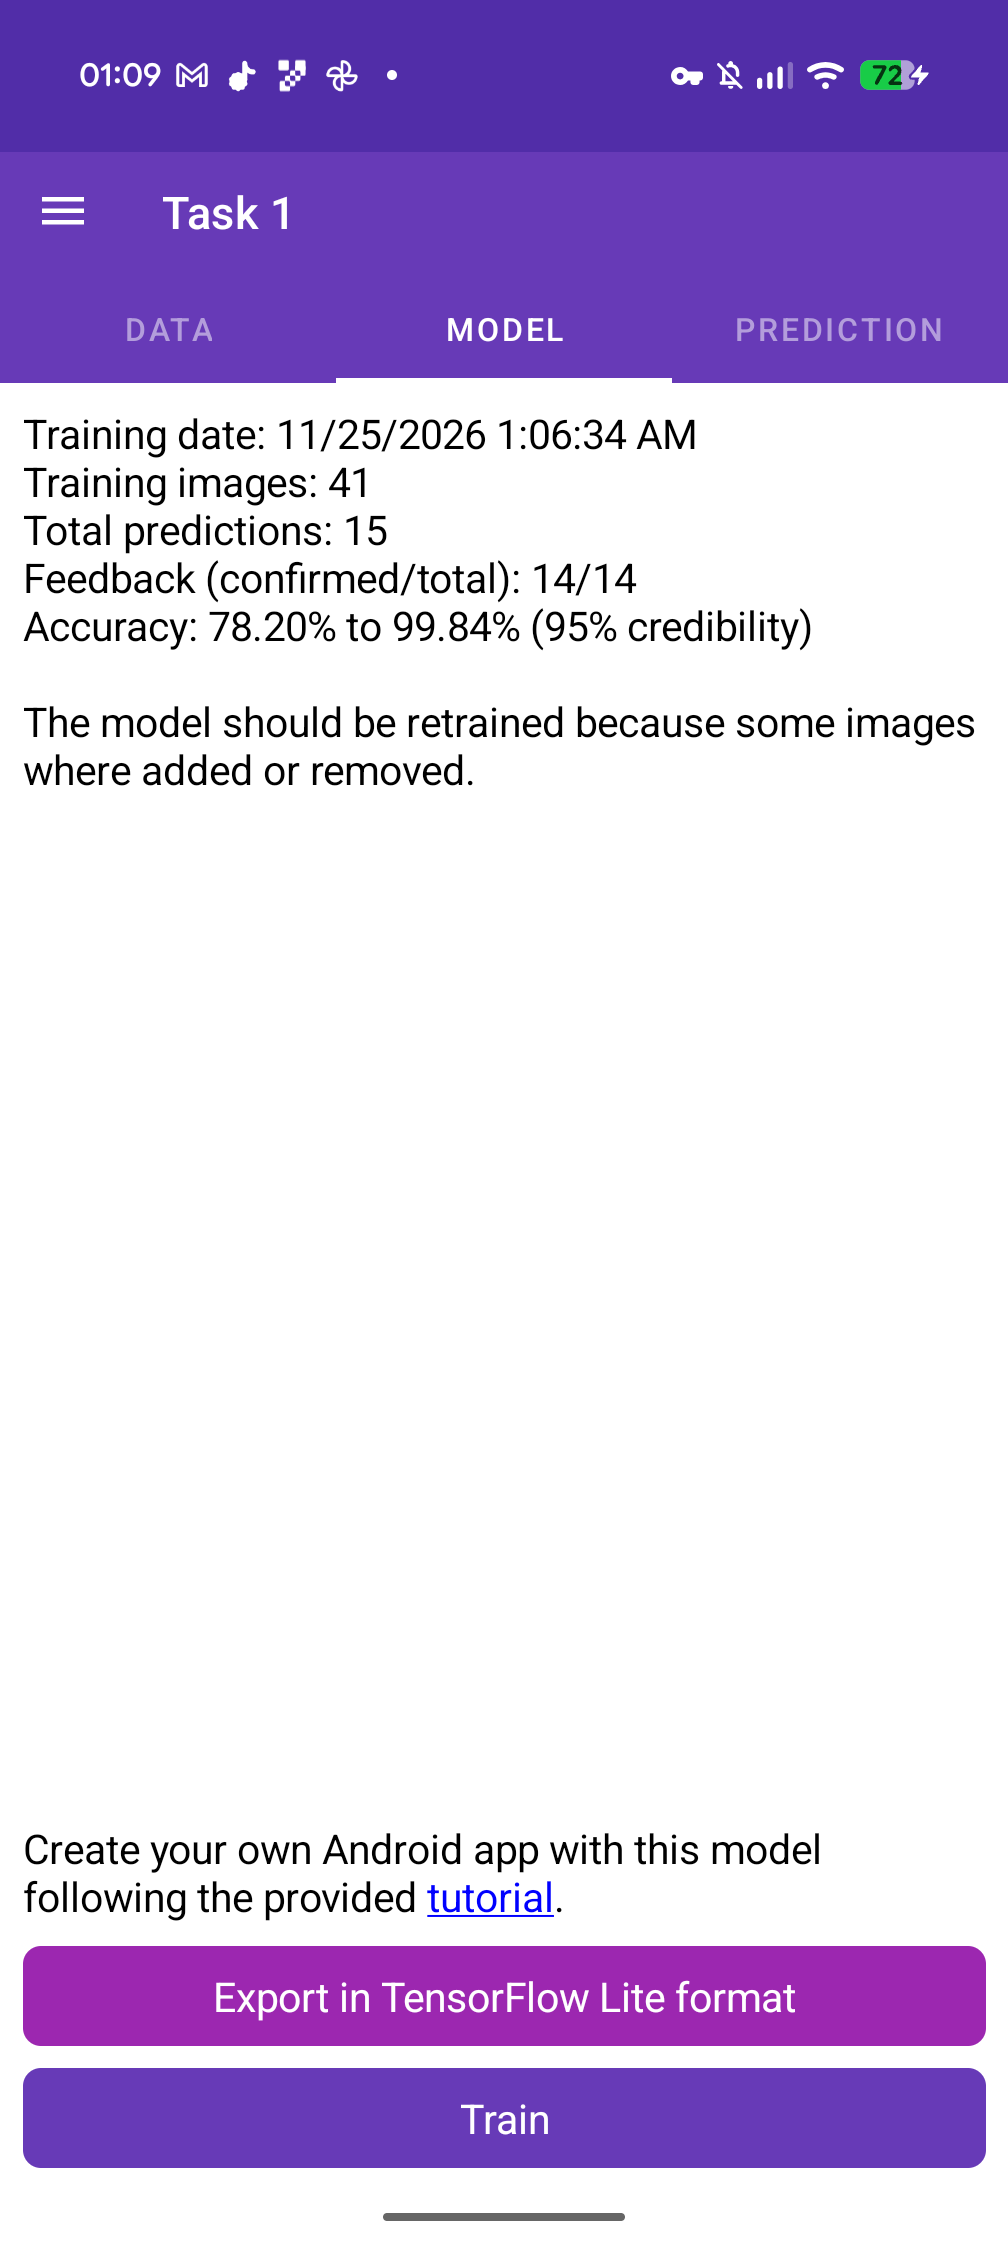

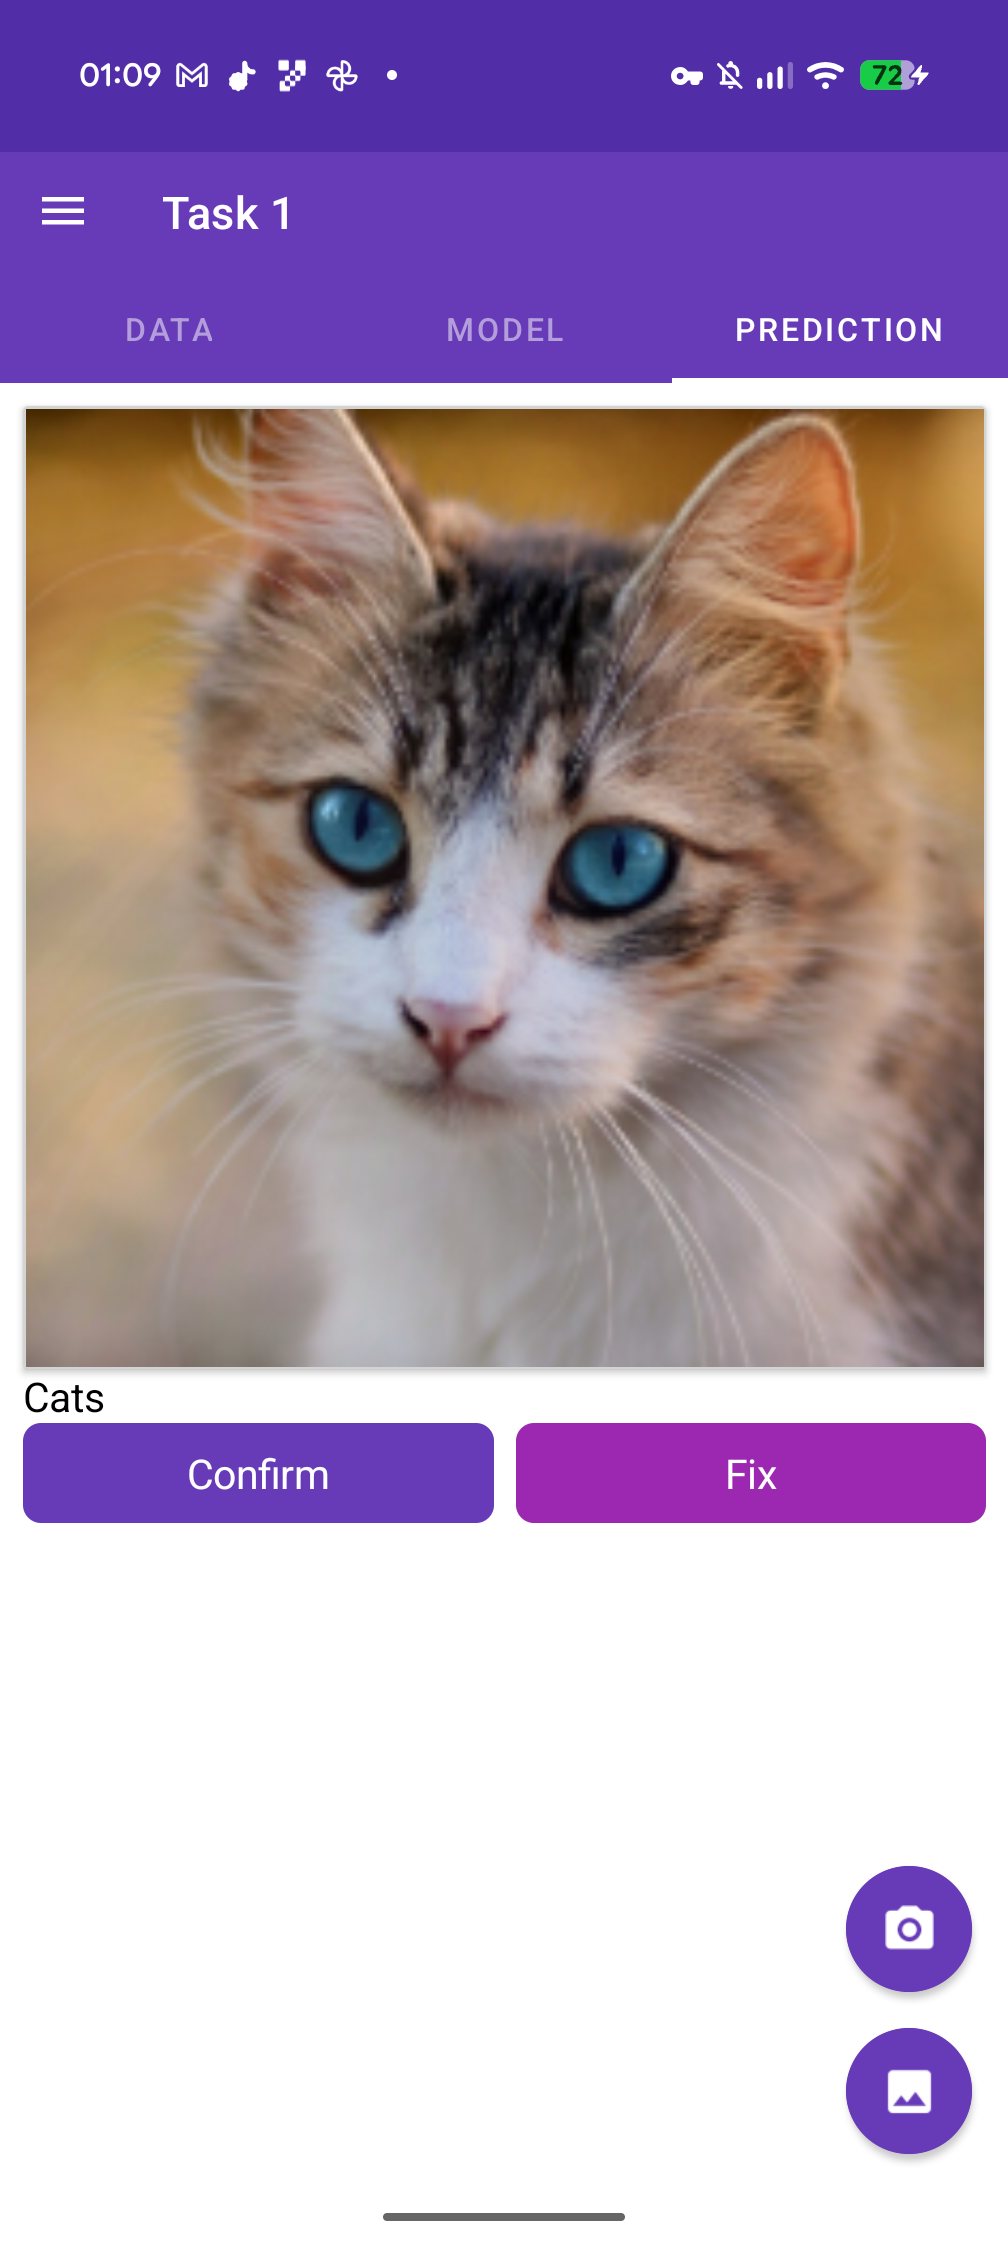

**Вывод о качестве и причинах ошибок:**
Модель на телефоне хорошо распознаёт три простых и разных класса, а повторное обучение с помощью **Confirm / Fix** реально помогает улучшить её точность. В наших проверках на чётких картинках она не ошибалась, но в обычных условиях подобные модели могут путаться по нескольким простым причинам:
1. Для обучения было мало фотографий (сначала всего по 10 картинок на класс).
2. На фото бывает лишний фон или другие объекты рядом (например, люди вокруг собаки или трава, закрывающая часть тела).
3. Плохое освещение, размытие или необычный ракурс мешают модели узнать объект.
4. Кошки и собаки похожего окраса и в похожей позе могут показаться модели похожими друг на друга.

## Задание 4.

1. Разработайте программный интерфейс для модели машинного обучения. API должен позволить приложению пользователя получить результат и точность распознавания.
2. Разработайте приложение с графическим интерфейсом, которое должно позволить загрузить изображение и с помощью разработанного API показать результат распознавания.

### Отчет по заданию 4 (API и приложение с графическим интерфейсом)

Я сделал простой программный интерфейс (API) и отдельное окно для пользователя на Python:
1. **`api.py` (библиотека FastAPI)** — загружает обученную модель `models/hotdog/keras_model.h5` и список классов `models/hotdog/labels.txt`. У сервиса есть адрес `POST /predict`, куда отправляется картинка, а в ответ возвращается JSON с названием класса (`class_name`) и уверенностью в процентах (`confidence`).
2. **`app.py` (библиотека Streamlit)** — простое веб-приложение с кнопкой выбора файла (`Выберите картинку`), предпросмотром фотографии и кнопкой `Проверить`. При нажатии оно отправляет файл в `api.py` на адрес `http://127.0.0.1:8000/predict` и выводит на экран класс и точность.

Для удобного запуска созданы два файла: `run_api.bat` (запускает API) и `run_app.bat` (запускает интерфейс).

Код **`api.py`**:
```python
from fastapi import FastAPI, UploadFile, File
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np
import io
import uvicorn

app = FastAPI()

model = load_model("models/hotdog/keras_model.h5", compile=False)
class_names = open("models/hotdog/labels.txt", "r", encoding="utf-8").readlines()


@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    contents = await file.read()
    image = Image.open(io.BytesIO(contents)).convert("RGB")
    size = (224, 224)
    image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
    image_array = np.asarray(image)
    normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
    data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
    data[0] = normalized_image_array

    prediction = model.predict(data)
    index = np.argmax(prediction)
    class_name = class_names[index].strip()
    if " " in class_name:
        class_name = class_name.split(" ", 1)[1]
    confidence = float(prediction[0][index])

    return {
        "class_name": class_name,
        "confidence": round(confidence * 100, 2)
    }


if __name__ == "__main__":
    uvicorn.run(app, host="127.0.0.1", port=8000)
```

Код **`app.py`**:
```python
import streamlit as st
import requests

st.title("Распознавание хот-догов")

uploaded_file = st.file_uploader("Выберите картинку", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    st.image(uploaded_file)

    if st.button("Проверить"):
        files = {"file": (uploaded_file.name, uploaded_file.getvalue(), uploaded_file.type)}
        response = requests.post("http://127.0.0.1:8000/predict", files=files)
        data = response.json()
        st.write("Класс:", data["class_name"])
        st.write("Точность:", data["confidence"], "%")
```

При проверке работы на фотографии `hot_dog_validation/133012.jpg` приложение вывело `Класс: хот-доги` и `Точность: 99.97 %` (а на картинке `not_hot_dog_validation/13023.jpg` API вернул `не хот-доги` с точностью `100.0 %`).

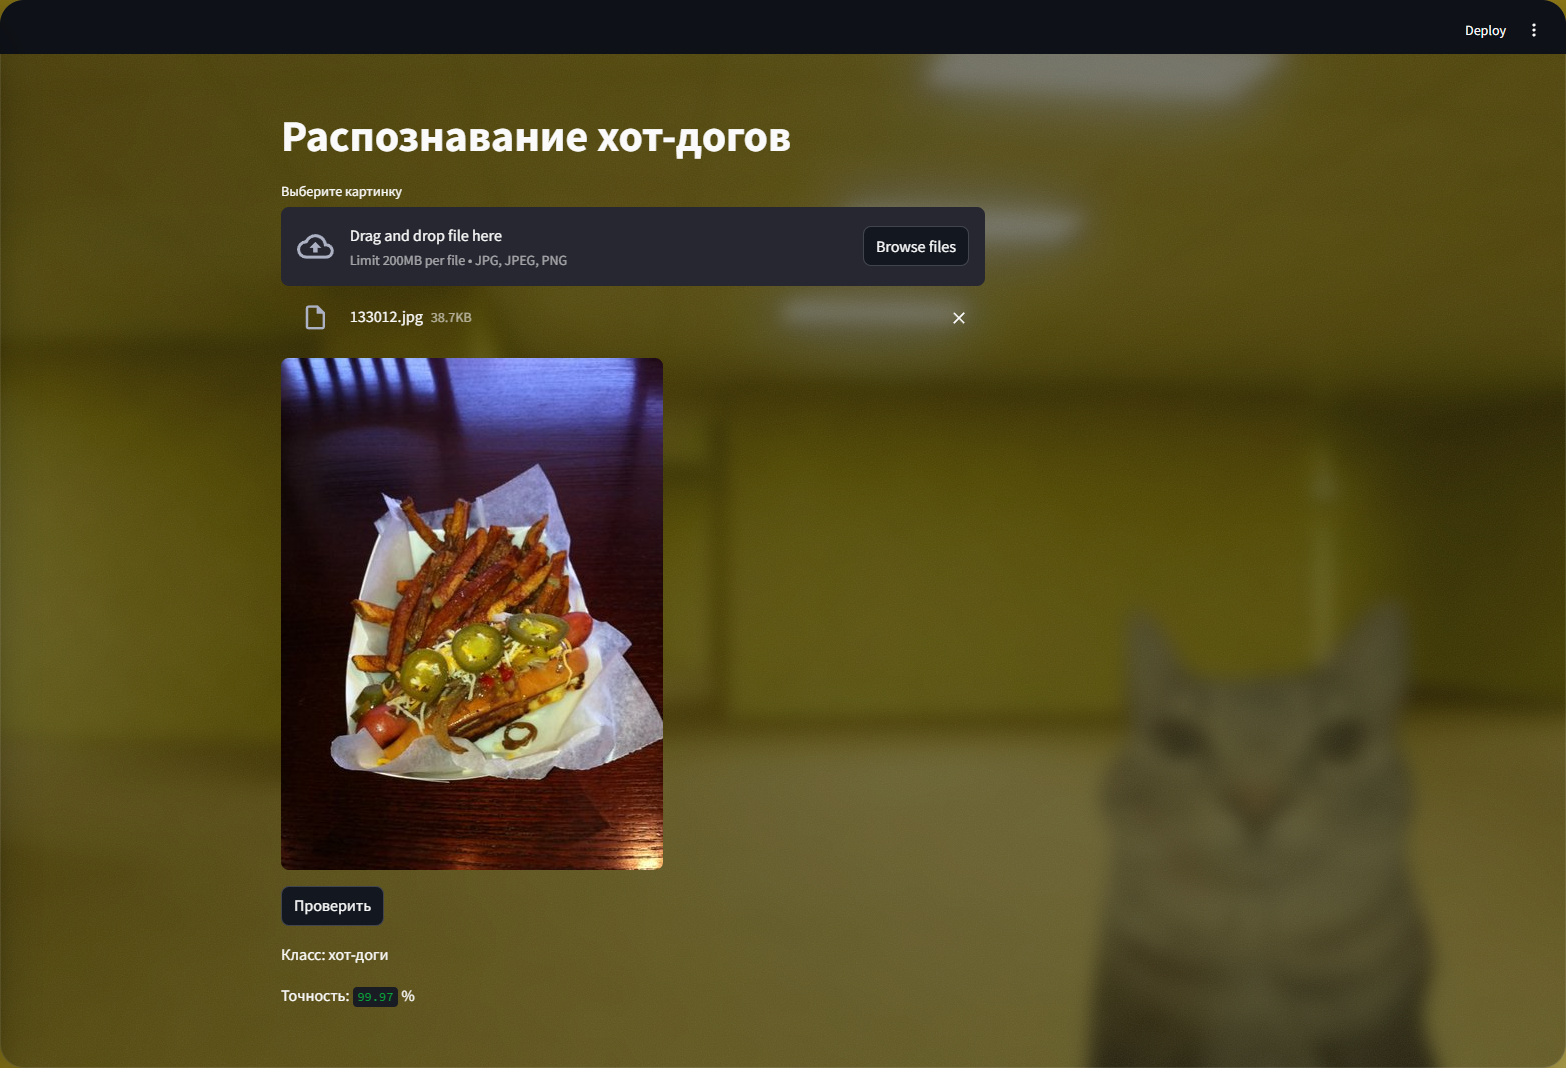